# Exploratory Data Analysis: Cold-Start Recipe Recommendation on Food.com

**Task.** Given a `(user_id, recipe_id)` pair where the recipe has **no reviews in the training data** (item cold-start), predict the **rating (1–5)** the user will give it. As a supplementary version, we also predict the probability that the rating is **5 stars** (a score in [0, 1]).

This notebook covers the dataset context, why we re-split the data by time, how the data was cleaned, and the statistics that motivate our modeling and evaluation choices. The cleaning itself is done by `preprocess.py`; here we only read its outputs (`data_clean/`) and, for context, the original Kaggle files.

**Contents**
1. Dataset context
2. Why we re-split by time
3. The cleaned splits
4. Rating distribution and the two targets
5. Long-tailed activity
6. The cold-start evaluation set
7. Recipe features: cleaning extreme values
8. Which features relate to the label?
9. Summary: implications for modeling

In [1]:
import ast
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("..")
import features as F                          # shared with the model notebooks

CLEAN = Path("../data_clean")                  # outputs of preprocess.py
RAW = Path("../../Assignment2/dataset_old")    # original Kaggle files (not in git)
VALID_START, TEST_START = pd.Timestamp("2013-01-01"), pd.Timestamp("2014-01-01")

# Plot style: one blue for single series, fixed categorical order for comparisons
BLUE, ORANGE, AQUA, RED, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#8a8984"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": "#0b0b0b",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "figure.dpi": 110,
})
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 1. Dataset context

The data comes from **Food.com** (formerly Genius Kitchen) and was released by Majumder et al., *"Generating Personalized Recipes from Historical User Preferences"* (EMNLP 2019). It contains 18 years of user reviews (2000–2018).

| File | Content |
|---|---|
| `RAW_interactions.csv` | every review: user, recipe, date, rating (0–5), review text |
| `RAW_recipes.csv` | 231k recipes: name, minutes, tags, nutrition, steps, ingredients, description, contributor, submission date |
| `PP_recipes.csv` / `PP_users.csv` | the authors' preprocessed subset (178k recipes): tokenized text, 58 cooking techniques, calorie level, ingredient ids |
| `interactions_{train,validation,test}.csv` | the authors' official split |

A rating of **0** means the user wrote a review without giving stars, so it carries no label.

In [2]:
raw_inter = pd.read_csv(RAW / "RAW_interactions.csv", usecols=["user_id", "recipe_id", "date", "rating"],
                        parse_dates=["date"])
print(f"{len(raw_inter):,} reviews, {raw_inter.user_id.nunique():,} users, {raw_inter.recipe_id.nunique():,} recipes")
print(f"rating == 0 (no stars): {(raw_inter.rating == 0).mean():.1%} of reviews")

1,132,367 reviews, 226,570 users, 231,637 recipes
rating == 0 (no stars): 5.4% of reviews


## 2. Why we re-split by time

Our models build a **profile of each user from their past reviews**. That is only honest if "past" really means *before* the review we are predicting. We checked the official split:

In [3]:
off_train = pd.read_csv(RAW / "interactions_train.csv", parse_dates=["date"])
off_test = pd.read_csv(RAW / "interactions_test.csv", parse_dates=["date"])
last_train_review = off_train.groupby("user_id").date.max()
sees_future = (last_train_review.reindex(off_test.user_id).values > off_test.date.values).mean()
print(f"Official split: {sees_future:.1%} of test users have training reviews dated AFTER their test review")

Official split: 82.7% of test users have training reviews dated AFTER their test review


For most test users, the official training file contains reviews written *after* the review we would be predicting, so any user-history feature would leak the future. We therefore rebuilt the splits from `RAW_interactions.csv` with a **global time cut**:

- **train**: before 2013-01-01
- **validation**: 2013
- **test**: 2014-01-01 onward

Activity on the site collapsed after 2008, so the later the cut, the fewer evaluation rows. We first used 2015 / 2016, which left only 489 validation and 894 test cold rows (19 and 45 of them below 4 stars), too few to tell models apart. Moving the cut to 2013 / 2014 costs only 6% of the training rows and gives 6,410 validation and 4,099 test cold rows. The cut was chosen for sample size, not for model results, and is fixed from here on.

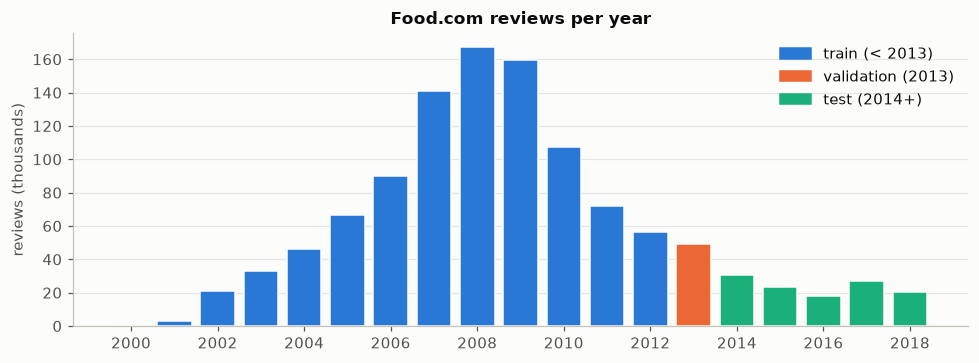

In [4]:
per_year = raw_inter.groupby(raw_inter.date.dt.year).size()
fig, ax = plt.subplots(figsize=(9, 3.4))
colors = [BLUE if y < VALID_START.year else (ORANGE if y < TEST_START.year else AQUA) for y in per_year.index]
ax.bar(per_year.index, per_year.values / 1000, color=colors, width=0.8, edgecolor="#fcfcfb", linewidth=1)
ax.set_ylabel("reviews (thousands)")
ax.set_title("Food.com reviews per year")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in (BLUE, ORANGE, AQUA)],
          labels=[f"train (< {VALID_START.year})", f"validation ({VALID_START.year})", f"test ({TEST_START.year}+)"], frameon=False)
ax.set_xticks(per_year.index[::2])
plt.tight_layout(); plt.show()

## 3. The cleaned splits

`preprocess.py` produces `data_clean/` with these steps (see `README.md` for full details):

| Step | Decision | Reason |
|---|---|---|
| Recipes | keep reviews of the 178k PP recipes; one review per user-recipe pair (earliest) | PP files give us techniques and calorie level |
| `rating == 0` | dropped (46,257 reviews) | no stars, no label |
| Users | keep users with ≥ 3 rated reviews **before 2013** | thin histories give unreliable profiles; deciding with the training period only avoids using the future |
| Time split | train < 2013 ≤ validation < 2014 ≤ test | no future information in user history |
| `n_fit`, `cold` | for each validation/test row, number of reviews its recipe has in the data the model is fit on (train for validation; train + validation for test); `cold = 1` when 0 | defines the cold-start evaluation rows |
| Recipe features | clip `minutes` and nutrition at the training p99, flag missing / extreme values | see Section 7 |

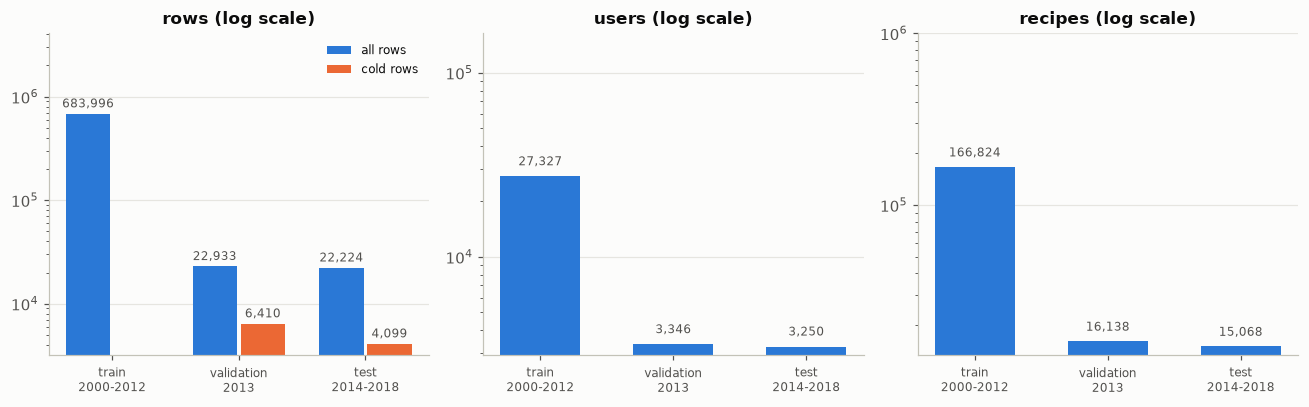

In [5]:
train = pd.read_csv(CLEAN / "interactions_train.csv", parse_dates=["date"])
valid = pd.read_csv(CLEAN / "interactions_validation.csv", parse_dates=["date"])
test = pd.read_csv(CLEAN / "interactions_test.csv", parse_dates=["date"])
splits = {"train": train, "validation": valid, "test": test}

overview = pd.DataFrame({
    name: {"rows": len(d), "users": d.user_id.nunique(), "recipes": d.recipe_id.nunique(),
           "cold rows": int(d.cold.sum()) if "cold" in d else 0}
    for name, d in splits.items()
}).T
ticks = [f"{name}\n{d.date.min().year}" + (f"-{d.date.max().year}" if d.date.max().year > d.date.min().year else "")
         for name, d in splits.items()]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
x, w = np.arange(len(overview)), 0.38
for ax, col in zip(axes, ["rows", "users", "recipes"]):
    if col == "rows":   # all rows next to the cold-start rows used for evaluation
        groups = [("all rows", overview["rows"], BLUE, -0.5), ("cold rows", overview["cold rows"], ORANGE, 0.5)]
    else:
        groups = [(col, overview[col], BLUE, 0)]
    for label, values, color, shift in groups:
        xs = x + shift * w
        keep = values.values > 0
        ax.bar(xs[keep], values.values[keep], w - 0.03 if len(groups) > 1 else 0.6, color=color, label=label)
        for xi, v in zip(xs[keep], values.values[keep]):
            ax.text(xi, v * 1.15, f"{v:,}", ha="center", fontsize=8, color="#52514e")
    ax.set_yscale("log")
    ax.set_ylim(top=overview[col].max() * 6)
    ax.set_xticks(x, ticks, fontsize=8)
    ax.set_title(f"{col} (log scale)")
    if len(groups) > 1:
        ax.legend(frameon=False, fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

## 4. Rating distribution and the two targets

Ratings on Food.com are heavily skewed towards 5 stars, in training and in the cold-start test rows alike.

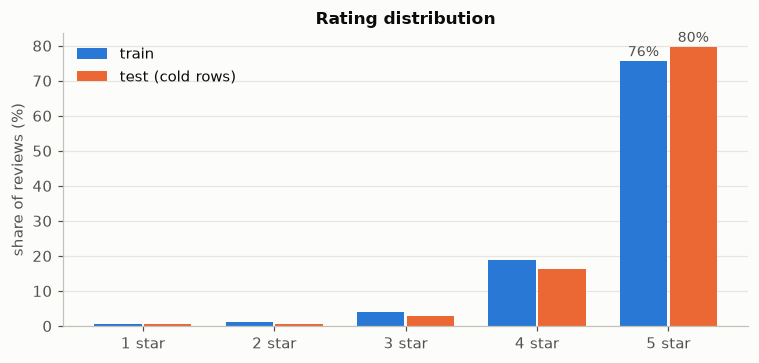

In [6]:
test_cold = test[test.cold == 1]
valid_cold = valid[valid.cold == 1]
dist = pd.DataFrame({
    "train": train.rating.value_counts(normalize=True),
    "test (cold rows)": test_cold.rating.value_counts(normalize=True),
}).sort_index().fillna(0)

fig, ax = plt.subplots(figsize=(7, 3.4))
x, w = np.arange(len(dist)), 0.38
for k, (col, color) in enumerate(zip(dist.columns, [BLUE, ORANGE])):
    bars = ax.bar(x + (k - 0.5) * w, dist[col] * 100, w - 0.02, color=color, label=col)
ax.set_xticks(x, [f"{r} star" for r in dist.index])
ax.set_ylabel("share of reviews (%)")
ax.set_title("Rating distribution")
ax.legend(frameon=False)
for k, col in enumerate(dist.columns):
    ax.text(x[-1] + (k - 0.5) * w, dist[col].iloc[-1] * 100 + 1.5, f"{dist[col].iloc[-1]:.0%}",
            ha="center", fontsize=9, color="#52514e")
plt.tight_layout(); plt.show()

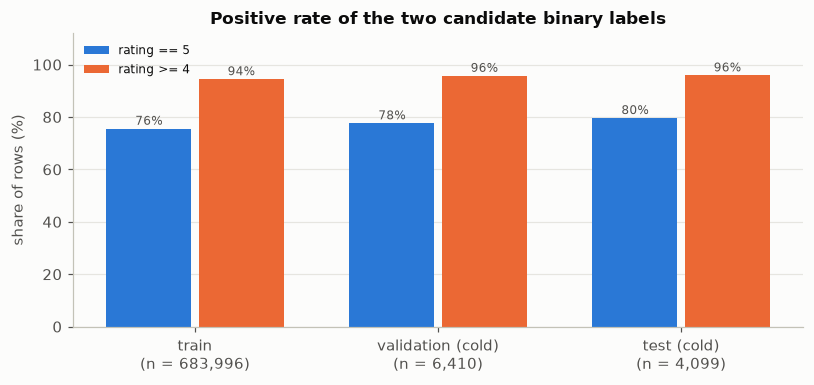

In [7]:
shares = {name: d for name, d in {"train": train, "validation (cold)": valid_cold, "test (cold)": test_cold}.items()}
fig, ax = plt.subplots(figsize=(7.5, 3.6))
x, w = np.arange(len(shares)), 0.38
for k, (label, fn, color) in enumerate([("rating == 5", lambda d: (d.rating == 5).mean(), BLUE),
                                        ("rating >= 4", lambda d: (d.rating >= 4).mean(), ORANGE)]):
    values = [fn(d) * 100 for d in shares.values()]
    ax.bar(x + (k - 0.5) * w, values, w - 0.03, color=color, label=label)
    for xi, v in zip(x + (k - 0.5) * w, values):
        ax.text(xi, v + 1.5, f"{v:.0f}%", ha="center", fontsize=8, color="#52514e")
ax.set_xticks(x, [f"{name}\n(n = {len(d):,})" for name, d in shares.items()])
ax.set_ylabel("share of rows (%)")
ax.set_ylim(0, 112)
ax.set_title("Positive rate of the two candidate binary labels")
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

**What this means for predicting the 1–5 rating.** Predicting the training mean for every cold test row already gives an MSE about equal to the variance of the ratings, and stars 1–3 are only ~4% of the rows. Improvements over the mean will look small in MSE and will be driven by a handful of low ratings:

In [8]:
mean_rating = train.rating.mean()
print(f"train mean rating = {mean_rating:.3f}")
print(f"MSE of always predicting it on test cold rows = {((test_cold.rating - mean_rating) ** 2).mean():.3f}")
print(f"variance of test cold ratings                 = {test_cold.rating.var(ddof=0):.3f}")

train mean rating = 4.677
MSE of always predicting it on test cold rows = 0.362
variance of test cold ratings                 = 0.358


We handle this in two ways:

- **Main task: rating (1–5), evaluated with MSE.** Because differences between models will be small, we report bootstrap confidence intervals and break the error down by true rating.
- **Supplementary task: `y = 1 if rating == 5`, evaluated with AUC.** AUC does not depend on a threshold or on the ~80% positive rate (a constant "always 5 stars" predictor would already reach ~80% accuracy), so it shows whether a model can *rank* recipes even when MSE barely moves. `rating >= 4` is not used: 95% of cold test rows would be positive, leaving almost no negatives.

## 5. Long-tailed activity

A few heavy users write a large share of the reviews, and most recipes have only a handful of reviews.

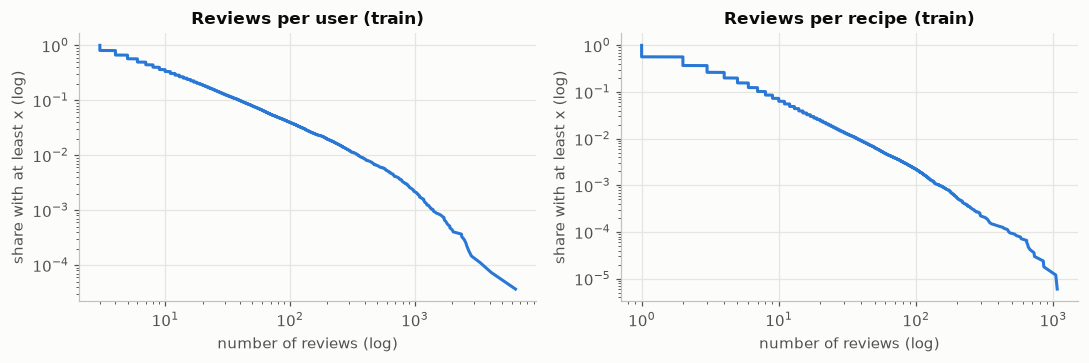

top 1% of users write 32.4% of training reviews; the most active user wrote 6,426
median reviews per recipe: 2; recipes with a single review: 43.2%


In [9]:
user_counts = train.user_id.value_counts()
recipe_counts = train.recipe_id.value_counts()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, counts, title in [(axes[0], user_counts, "Reviews per user (train)"),
                          (axes[1], recipe_counts, "Reviews per recipe (train)")]:
    values = np.sort(counts.values)
    ccdf = 1 - np.arange(len(values)) / len(values)
    ax.loglog(values, ccdf, color=BLUE)
    ax.set_xlabel("number of reviews (log)")
    ax.set_ylabel("share with at least x (log)")
    ax.set_title(title)
    ax.grid(True, which="major", axis="both")
plt.tight_layout(); plt.show()

top1 = user_counts.nlargest(int(len(user_counts) * 0.01)).sum() / len(train)
print(f"top 1% of users write {top1:.1%} of training reviews; the most active user wrote {user_counts.max():,}")
print(f"median reviews per recipe: {recipe_counts.median():.0f}; recipes with a single review: {(recipe_counts == 1).mean():.1%}")

**Implication.** Without correction, a model trained on all rows would mostly learn the tastes of a few heavy users. We will down-weight them during training (e.g. sample weight $1/\sqrt{n_u}$).

## 6. The cold-start evaluation set

Only the validation/test rows whose recipe has no reviews in the training data (`cold == 1`) are used to evaluate the cold-start task. The remaining "warm" rows are kept as a comparison.

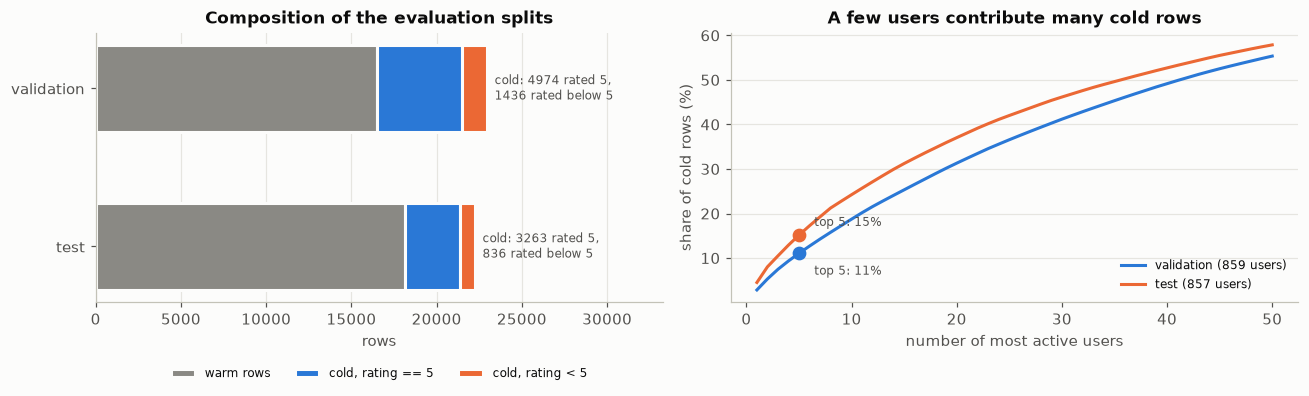

validation: 6410 cold rows (28.0%), 859 users, 4727 recipes; most rows from one user: 182
test: 4099 cold rows (18.4%), 857 users, 3268 recipes; most rows from one user: 185


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

# left: what each evaluation split is made of
names = ["validation", "test"]
parts = [("warm rows", lambda d: (d.cold == 0).sum(), GRAY),
         ("cold, rating == 5", lambda d: ((d.cold == 1) & (d.rating == 5)).sum(), BLUE),
         ("cold, rating < 5", lambda d: ((d.cold == 1) & (d.rating < 5)).sum(), ORANGE)]
left = np.zeros(2)
for label, fn, color in parts:
    values = np.array([fn(d) for d in (valid, test)])
    axes[0].barh(names, values, left=left, color=color, edgecolor="#fcfcfb", linewidth=2, height=0.55, label=label)
    left += values
for yi, d in enumerate((valid, test)):
    c = d[d.cold == 1]
    axes[0].text(left[yi], yi, f"  cold: {(c.rating == 5).sum()} rated 5,\n  {(c.rating < 5).sum()} rated below 5",
                 va="center", fontsize=8, color="#52514e")
axes[0].set_xlim(0, left.max() * 1.45)
axes[0].set_xlabel("rows")
axes[0].set_title("Composition of the evaluation splits")
axes[0].legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
axes[0].grid(True, axis="x"); axes[0].grid(False, axis="y")
axes[0].invert_yaxis()

# right: how concentrated the cold rows are on a few users
top = np.arange(1, 51)
for name, d, color in [("validation", valid, BLUE), ("test", test, ORANGE)]:
    per_user = d[d.cold == 1].user_id.value_counts().values
    share = np.cumsum(per_user)[top - 1] / per_user.sum() * 100
    axes[1].plot(top, share, color=color, label=f"{name} ({len(per_user)} users)")
    axes[1].plot(5, share[4], "o", color=color, markersize=8)
    axes[1].annotate(f"top 5: {share[4]:.0f}%", (5, share[4]), xytext=(10, 6 if name == "test" else -14),
                     textcoords="offset points", fontsize=8, color="#52514e")
axes[1].set_xlabel("number of most active users")
axes[1].set_ylabel("share of cold rows (%)")
axes[1].set_title("A few users contribute many cold rows")
axes[1].legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

for name, d in [("validation", valid), ("test", test)]:
    c = d[d.cold == 1]
    print(f"{name}: {len(c)} cold rows ({len(c) / len(d):.1%}), {c.user_id.nunique()} users, {c.recipe_id.nunique()} recipes; "
          f"most rows from one user: {c.user_id.value_counts().max()}")

Two consequences for evaluation:

- The test set has **836 negatives** (169 of them below 4 stars), so model differences in MSE will be small relative to their noise. We will report **95% bootstrap confidence intervals** and paired comparisons.
- The **top 5 users contribute 11–15% of cold rows**, so the bootstrap resamples **users**, not rows.

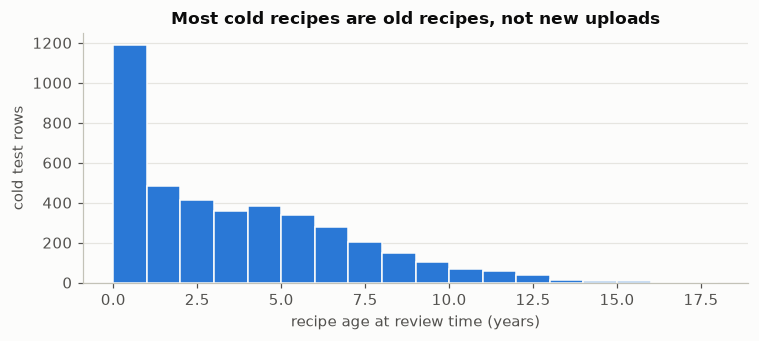

cold test rows whose recipe was submitted in 2014 or later: 23.9%


In [11]:
recipes = pd.read_csv(CLEAN / "RAW_recipes_clean.csv", parse_dates=["submitted"])
recipes["description"] = recipes["description"].fillna("")
submitted = recipes.set_index("id").submitted

test_cold = test_cold.assign(age_years=(test_cold.date - submitted.reindex(test_cold.recipe_id).values).dt.days / 365.25)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(test_cold.age_years, bins=np.arange(0, 19, 1), color=BLUE, edgecolor="#fcfcfb", linewidth=1)
ax.set_xlabel("recipe age at review time (years)")
ax.set_ylabel("cold test rows")
ax.set_title("Most cold recipes are old recipes, not new uploads")
plt.tight_layout(); plt.show()

print(f"cold test rows whose recipe was submitted in {TEST_START.year} or later: {(submitted.reindex(test_cold.recipe_id) >= TEST_START).mean():.1%}")

"Cold" means *no reviews in the data the model is trained on*, not necessarily "just uploaded": about 70% of cold test rows are for recipes that had been online for more than a year but were never reviewed by the users in our training data. Recipe age (review date − submission date) is known at prediction time, so we keep it as a feature.

### Building cold-start training examples

The training split contains no cold rows by construction, so we simulate them: reviews written **on the first day a recipe was reviewed** were, at that moment, reviews of a recipe with no prior reviews. These rows match the evaluation setting. We use the same function as the models (`features.pseudo_cold_rows`); a recipe can have several reviews on its first day, so there are slightly more rows than recipes. The models additionally require at least 3 earlier ratings by the user (Section 8).

In [12]:
first = F.pseudo_cold_rows(train)   # all reviews on the first day each recipe was reviewed; adds y = (rating == 5)
print(f"recipes in train: {train.recipe_id.nunique():,}; pseudo-cold training rows: {len(first):,}")
print(f"share rating == 5: {first.y.mean():.1%}")

recipes in train: 166,824; pseudo-cold training rows: 169,023
share rating == 5: 71.9%


## 7. Recipe features: cleaning extreme values

The raw recipe data contains impossible values. `minutes` and the seven nutrition values (calories plus six % daily values) are clipped at the 99th percentile of recipes in the training split, with flags recording what was changed.

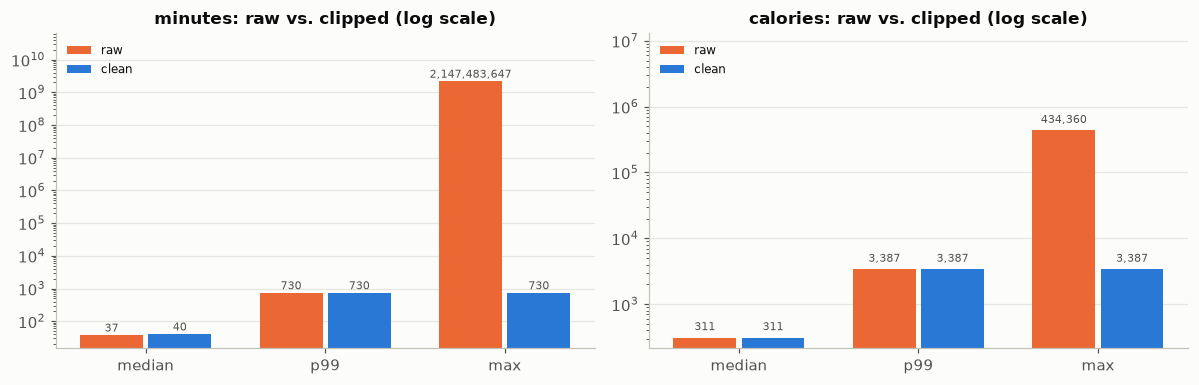

In [13]:
raw_recipes = pd.read_csv(RAW / "RAW_recipes.csv", usecols=["id", "minutes", "nutrition"])
raw_recipes = raw_recipes[raw_recipes.id.isin(recipes.id)]
raw_recipes["calories"] = raw_recipes.nutrition.map(lambda s: ast.literal_eval(s)[0])

q, stats = [0.5, 0.99, 1.0], ["median", "p99", "max"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
x, w = np.arange(len(q)), 0.38
for ax, col in zip(axes, ["minutes", "calories"]):
    for k, (label, frame, color) in enumerate([("raw", raw_recipes, ORANGE), ("clean", recipes, BLUE)]):
        values = frame[col].quantile(q).values
        ax.bar(x + (k - 0.5) * w, values, w - 0.03, color=color, label=label)
        for xi, v in zip(x + (k - 0.5) * w, values):
            ax.text(xi, v * 1.3, f"{v:,.0f}", ha="center", fontsize=7, color="#52514e")
    ax.set_yscale("log")
    ax.set_ylim(top=raw_recipes[col].max() * 30)
    ax.set_xticks(x, stats)
    ax.set_title(f"{col}: raw vs. clipped (log scale)")
    ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

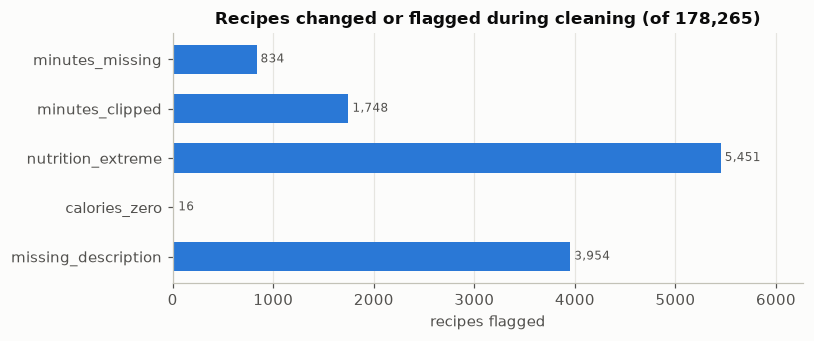

In [14]:
flags = recipes.assign(missing_description=1 - recipes.has_description)[
    ["minutes_missing", "minutes_clipped", "nutrition_extreme", "calories_zero", "missing_description"]].sum()
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.barh(flags.index, flags.values, color=BLUE, height=0.6)
for yi, v in enumerate(flags.values):
    ax.text(v, yi, f" {v:,}", va="center", fontsize=8, color="#52514e")
ax.invert_yaxis()
ax.set_xlabel("recipes flagged")
ax.set_xlim(0, flags.max() * 1.15)
ax.set_title(f"Recipes changed or flagged during cleaning (of {len(recipes):,})")
ax.grid(True, axis="x"); ax.grid(False, axis="y")
plt.tight_layout(); plt.show()

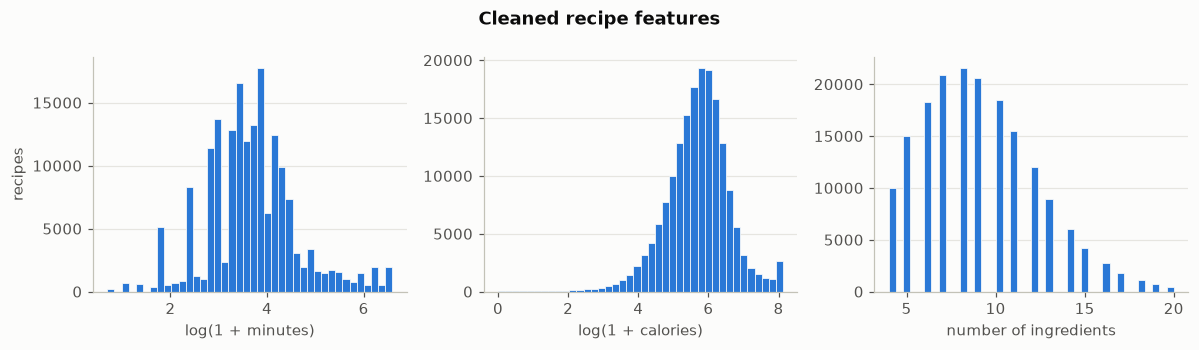

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, col, label in [(axes[0], "minutes", "log(1 + minutes)"),
                       (axes[1], "calories", "log(1 + calories)"),
                       (axes[2], "n_ingredients", "number of ingredients")]:
    values = np.log1p(recipes[col]) if col != "n_ingredients" else recipes[col]
    ax.hist(values, bins=40, color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
    ax.set_xlabel(label)
axes[0].set_ylabel("recipes")
fig.suptitle("Cleaned recipe features", fontweight="bold")
plt.tight_layout(); plt.show()

### How the recipe features relate to each other

Spearman rank correlation (robust to the skewed distributions) between the numeric recipe features, over the recipes reviewed in the training split.

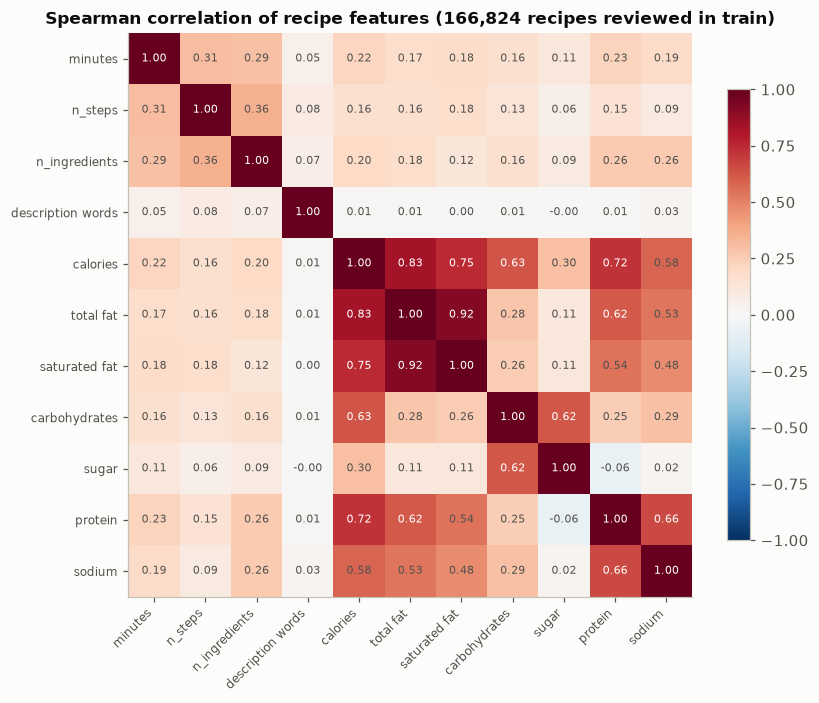

In [16]:
import plots as P   # shared heatmap helper (the plot style above is kept)

reviewed = recipes[recipes.id.isin(train.recipe_id)]
num = pd.DataFrame({"minutes": reviewed.minutes, "n_steps": reviewed.n_steps, "n_ingredients": reviewed.n_ingredients,
                    "description words": reviewed.description.str.split().str.len(),
                    "calories": reviewed.calories, "total fat": reviewed.total_fat_pdv, "saturated fat": reviewed.saturated_fat_pdv,
                    "carbohydrates": reviewed.carbohydrates_pdv, "sugar": reviewed.sugar_pdv,
                    "protein": reviewed.protein_pdv, "sodium": reviewed.sodium_pdv})
corr = num.corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.8, 6.4))
im = P.heatmap(ax, corr, title=f"Spearman correlation of recipe features ({len(reviewed):,} recipes reviewed in train)")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

**Reading the heatmap.** The seven nutrition values form one tightly correlated block: total fat and saturated fat 0.92, calories and total fat 0.83, calories and protein 0.72, because calories are largely made of fat, carbohydrates and protein. Sugar goes with carbohydrates (0.62) but not with protein (−0.06). Recipe complexity is only moderately linked: steps and ingredients 0.36, minutes and steps 0.31. Description length is unrelated to everything else.

Consequences for modeling: the nutrition columns are partly redundant, so a linear model needs regularization (ridge) and its individual nutrition coefficients should not be read one by one; tree models are unaffected in accuracy but split the importance among correlated columns. No column is a near-copy of another (all below 0.95), so all are kept.

After clipping, `minutes` and `calories` are still right-skewed, so the models will use their logs. `n_steps` (3–37) and `n_ingredients` (4–20) were already filtered by the dataset authors.

## 8. Which features relate to the label?

To avoid peeking at the evaluation data, all feature–label analysis below uses **only the pseudo-cold training rows** from Section 6.

### Recipe content

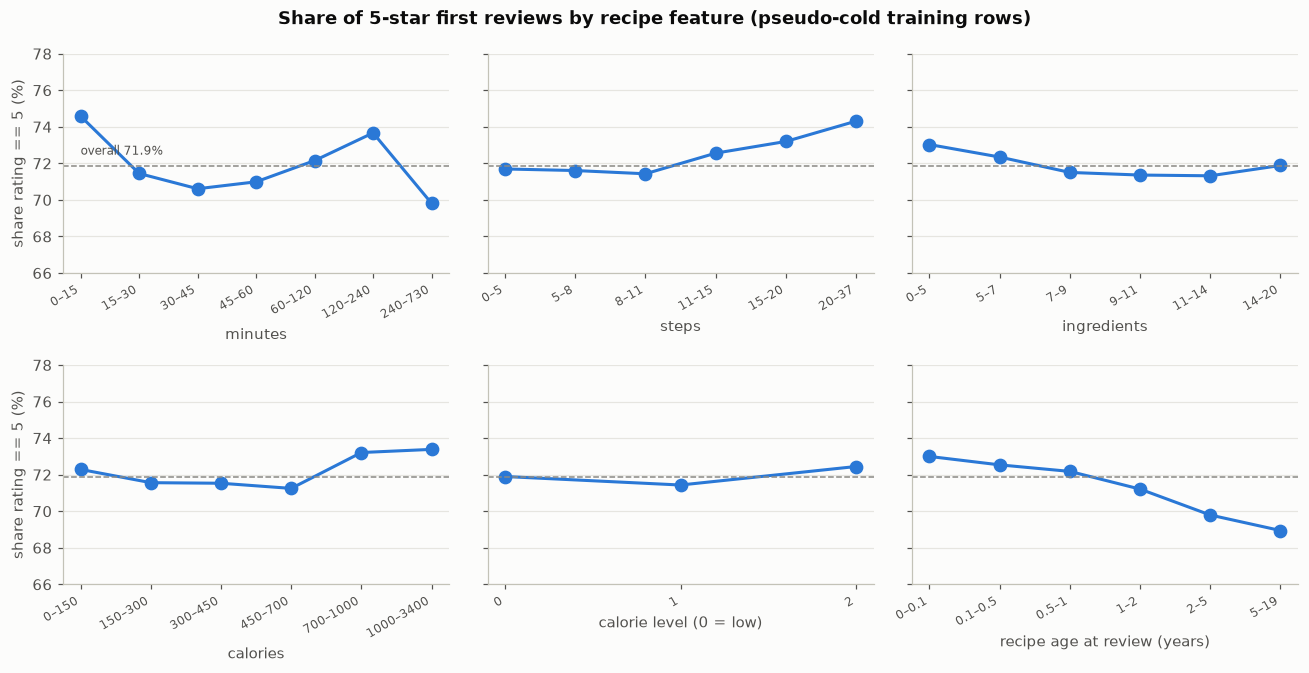

In [17]:
first = first.merge(recipes[["id", "minutes", "n_steps", "n_ingredients", "calories", "submitted", "tags", "contributor_id"]],
                    left_on="recipe_id", right_on="id", how="left")
pp = pd.read_csv(RAW / "PP_recipes.csv", usecols=["id", "calorie_level"])
first = first.merge(pp, on="id", how="left")
first["age_years"] = (first.date - first.submitted).dt.days / 365.25
base_rate = first.y.mean()

def rate_by_bin(col, bins):
    # share of 5-star rows per bin; bins=None groups by the raw (categorical) value
    if bins is None:
        r = first.groupby(col).y.agg(["mean", "size"])
        return r, [str(int(v)) for v in r.index]
    r = first.groupby(pd.cut(first[col], bins), observed=True).y.agg(["mean", "size"])
    return r, [f"{max(i.left, 0):g}–{i.right:g}" for i in r.index]

panels = [
    ("minutes", [0, 15, 30, 45, 60, 120, 240, 730], "minutes"),
    ("n_steps", [0, 5, 8, 11, 15, 20, 37], "steps"),
    ("n_ingredients", [0, 5, 7, 9, 11, 14, 20], "ingredients"),
    ("calories", [-1, 150, 300, 450, 700, 1000, 3400], "calories"),
    ("calorie_level", None, "calorie level (0 = low)"),
    ("age_years", [-1, 0.1, 0.5, 1, 2, 5, 19], "recipe age at review (years)"),
]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.2), sharey=True)
for ax, (col, bins, label) in zip(axes.flat, panels):
    r, names = rate_by_bin(col, bins)
    ax.plot(range(len(r)), r["mean"] * 100, color=BLUE, marker="o", markersize=8)
    ax.axhline(base_rate * 100, color=GRAY, linestyle="--", linewidth=1)
    ax.set_xticks(range(len(r)), names, rotation=30, ha="right", fontsize=8)
    ax.set_xlabel(label)
    ax.set_ylim(66, 78)
for ax in axes[:, 0]:
    ax.set_ylabel("share rating == 5 (%)")
axes[0, 0].text(0, base_rate * 100 + 0.6, f"overall {base_rate:.1%}", color="#52514e", fontsize=8)
fig.suptitle("Share of 5-star first reviews by recipe feature (pseudo-cold training rows)", fontweight="bold")
plt.tight_layout(); plt.show()

### Tags

Each recipe carries ~18 tags. Below are the tags whose recipes deviate most from the overall 5-star rate (tags present on at least 2,000 pseudo-cold rows).

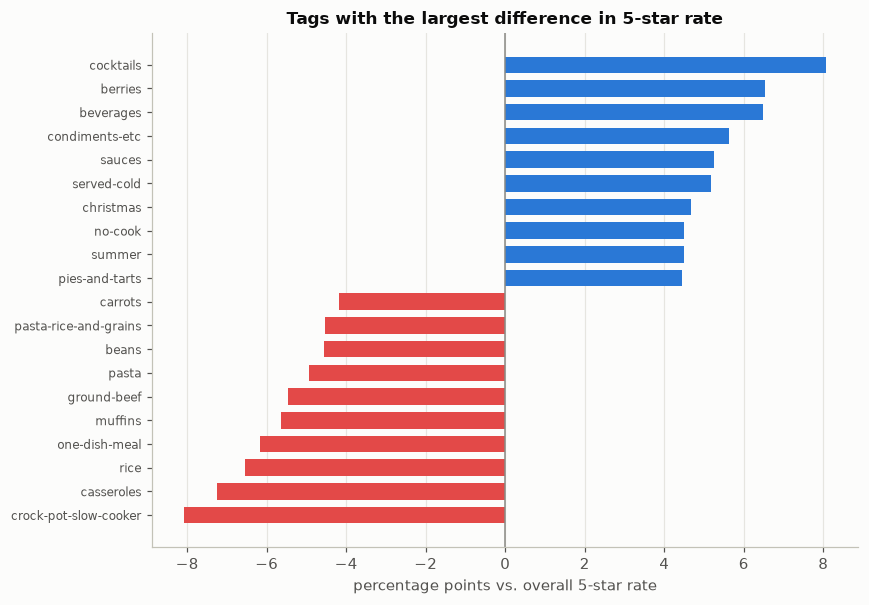

157 tags with >= 2,000 rows


In [18]:
tag_rows = first[["y", "tags"]].assign(tag=first.tags.map(ast.literal_eval)).explode("tag")
tag_stats = tag_rows.groupby("tag").y.agg(["mean", "size"])
tag_stats = tag_stats[tag_stats["size"] >= 2000]
tag_stats["diff"] = (tag_stats["mean"] - base_rate) * 100
shown = pd.concat([tag_stats.nsmallest(10, "diff"), tag_stats.nlargest(10, "diff").iloc[::-1]])

fig, ax = plt.subplots(figsize=(8, 5.6))
ax.barh(range(len(shown)), shown["diff"], color=[RED if d < 0 else BLUE for d in shown["diff"]], height=0.7)
ax.set_yticks(range(len(shown)), shown.index, fontsize=8)
ax.axvline(0, color=GRAY, linewidth=1)
ax.set_xlabel("percentage points vs. overall 5-star rate")
ax.set_title("Tags with the largest difference in 5-star rate")
ax.grid(True, axis="x"); ax.grid(False, axis="y")
plt.tight_layout(); plt.show()
print(f"{len(tag_stats)} tags with >= 2,000 rows")

### User history (time-aware)

For each pseudo-cold row we compute the user's share of 5-star ratings using **only reviews written strictly before that date**, exactly as the features will be built for the model.

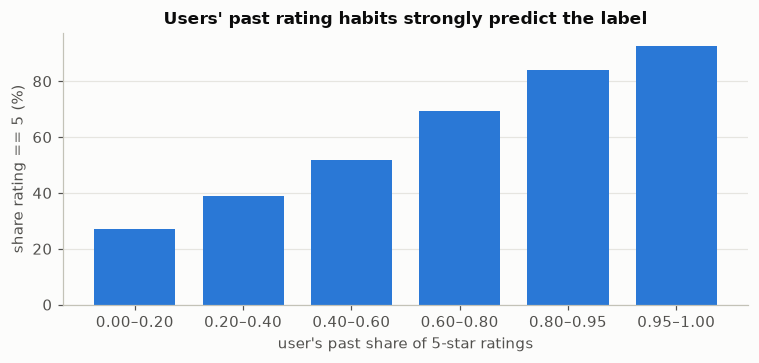

rows with >= 3 prior ratings: 89.9% of pseudo-cold rows


In [19]:
daily = train.assign(y=(train.rating == 5).astype(int)).groupby(["user_id", "date"]).y.agg(n="size", n5="sum").reset_index()
daily[["prior_n", "prior_n5"]] = daily.groupby("user_id")[["n", "n5"]].cumsum().values - daily[["n", "n5"]].values
first = first.merge(daily[["user_id", "date", "prior_n", "prior_n5"]], on=["user_id", "date"], how="left")
has_history = first.prior_n >= 3
first.loc[has_history, "prior_rate"] = first.prior_n5 / first.prior_n

r = first[has_history].groupby(pd.cut(first.prior_rate, [0, 0.2, 0.4, 0.6, 0.8, 0.95, 1.0], include_lowest=True),
                               observed=True).y.agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(range(len(r)), r["mean"] * 100, color=BLUE, width=0.75)
ax.set_xticks(range(len(r)), [f"{max(i.left, 0):.2f}–{i.right:.2f}" for i in r.index])
ax.set_xlabel("user's past share of 5-star ratings")
ax.set_ylabel("share rating == 5 (%)")
ax.set_title("Users' past rating habits strongly predict the label")
plt.tight_layout(); plt.show()
print(f"rows with >= 3 prior ratings: {has_history.mean():.1%} of pseudo-cold rows")

### Author history

A recipe's contributor may have other, already-reviewed recipes. We compute each author's 5-star share over reviews of their **other** recipes before the review date. (No cold test row is a user reviewing their own recipe, so "user is the author" is not used.)

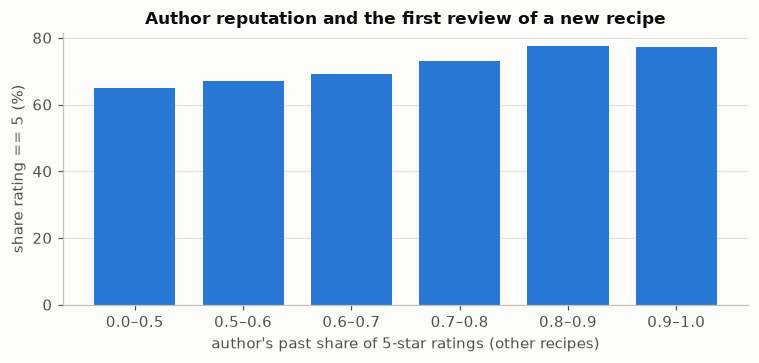

rows whose author has >= 5 earlier reviews: 75.7%


In [20]:
author_daily = (train.merge(recipes[["id", "contributor_id"]], left_on="recipe_id", right_on="id")
                .assign(y=lambda d: (d.rating == 5).astype(int))
                .groupby(["contributor_id", "date"]).y.agg(n="size", n5="sum").reset_index())
author_daily[["a_n", "a_n5"]] = author_daily.groupby("contributor_id")[["n", "n5"]].cumsum().values - author_daily[["n", "n5"]].values
first = first.merge(author_daily[["contributor_id", "date", "a_n", "a_n5"]], on=["contributor_id", "date"], how="left")
has_author = first.a_n >= 5
first.loc[has_author, "author_rate"] = first.a_n5 / first.a_n

r = first[has_author].groupby(pd.cut(first.author_rate, [0, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0], include_lowest=True),
                              observed=True).y.agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(range(len(r)), r["mean"] * 100, color=BLUE, width=0.75)
ax.set_xticks(range(len(r)), [f"{max(i.left, 0):.1f}–{i.right:.1f}" for i in r.index])
ax.set_xlabel("author's past share of 5-star ratings (other recipes)")
ax.set_ylabel("share rating == 5 (%)")
ax.set_title("Author reputation and the first review of a new recipe")
plt.tight_layout(); plt.show()
print(f"rows whose author has >= 5 earlier reviews: {has_author.mean():.1%}")

## 9. Summary: implications for modeling

| Finding | Implication |
|---|---|
| The official split leaks the future for 82.7% of test users | re-split globally by time; user features use only earlier reviews |
| ~80% of ratings are 5 stars; a constant mean already matches the variance in MSE | main task: predict the 1–5 rating (MSE, with CIs and errors by true rating); supplementary: P(rating == 5) evaluated with AUC |
| Activity collapsed after 2008; with the 2013 / 2014 cut there are 4,099 cold test rows (836 negatives, 169 below 4 stars) | report user-level bootstrap confidence intervals and paired comparisons |
| A few heavy users dominate both training and cold test rows | down-weight heavy users in training; resample users in the bootstrap |
| Training has no cold rows | train on the reviews from each recipe's first review day (169k pseudo-cold rows; 152k after requiring ≥ 3 earlier user ratings) |
| Most cold recipes are old, rarely-reviewed recipes | recipe age is a legitimate feature |
| Raw `minutes` and nutrition contain impossible values | clip at the training p99, add flags, use logs |
| User and author history show the strongest relationship with the label; recipe content shows smaller but consistent effects | expect user features to carry most of the signal; the question for cold-start is how much recipe content and user × recipe matching add on top (ablation) |